# 3. The cube and the regular tetrahedron
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/3_cube.ipynb)

**Notebooks:** [1. Sphere](1_sphere.ipynb) · [2. Torus](2_torus.ipynb) · **3. Cube & tetrahedron** · [4. NASA almond](4_almond.ipynb)

Unlike the sphere and the torus, the unit cube $[-\tfrac12,\tfrac12]^3$ has flat faces meeting at sharp edges and corners, so the continued field is singular on the edges themselves and no closed surface inside the body can enclose the singularities (Sections 4 and 5 of the paper). Placing dipoles on a scaled inner cube therefore stalls above 20% error.

In [1]:
# Set up paths (and get the code and the data when run on Colab)
import os, subprocess, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/MFS"):
        subprocess.run(["git", "clone", "-q", "https://github.com/sap6/MFS", "/content/MFS"], check=True)
    os.chdir("/content/MFS/notebooks")            # numpy, scipy, numba and matplotlib come with Colab
elif os.path.isdir("notebooks") and os.path.isdir("mfs"):
    os.chdir("notebooks")
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import core, cube

pts = 2.0 * core.fibonacci(400)            # field error is measured on the enclosing sphere of radius 2
ref = cube.solve(9, pts=pts)[0]            # fine layout as our reference (~50 s on 2 cores; the paper uses J = 12)

## Why a scaled inner cube stalls
With electric dipoles on the faces of a concentric inner cube of side 0.6, adding more dipoles leaves the scattered-field error stuck between 20% and 30%.

In [3]:
for n in (4, 6, 8, 10):
    E, t, info = cube.solve(None, pts=pts, n_base=n)
    print(f"{6 * n * n:4d} dipoles on inner cube: relative error {core.rel(E, ref):.0%}")

  96 dipoles on inner cube: relative error 30%
 216 dipoles on inner cube: relative error 25%


 384 dipoles on inner cube: relative error 23%
 600 dipoles on inner cube: relative error 21%


## Sources on the medial skeleton and the singular tail
By Theorem 1 of the paper, the scattered field of a convex conducting polyhedron equals the field of electric and magnetic currents on its interior medial surface (*skeleton*): for the cube, the twelve diagonal bisector triangles joining the edges to the centre. Our layout at level $J$ therefore places:
1. **Edge lines** on each bisector plane at depths $d_j = 0.2 \cdot 2^{-j/2}$ down to $d_{\min} = 0.2 \cdot 2^{-J}$, carrying Legendre modes in a log-stretched variable towards the vertices;
2. **Vertex dipoles** on the body diagonals and a coarse $8\times 8$ **base grid** on an inner cube for the smooth interior remainder;
3. **Singular tails** continuing the lines from $d_{\min}$ down to $2^{-9}d_{\min}$ with fixed Meixner edge weights ($e = 2/3, 5/3, 4/3, 7/3$, Table 1) and cone vertex weights, narrowing the uncancelled boundary strip by more than a hundredfold (Figures 3, 5 and 6).

J = 2:  5160 whole-cube unknowns (645 per class), error 3.5e-02 (no tail 9.6e-02), 0.7 s


J = 3:  7008 whole-cube unknowns (876 per class), error 1.4e-02 (no tail 6.9e-02), 1.3 s


J = 4:  9024 whole-cube unknowns (1128 per class), error 5.2e-03 (no tail 4.9e-02), 1.1 s


J = 5: 12984 whole-cube unknowns (1623 per class), error 1.9e-03 (no tail 3.3e-02), 2.1 s


J = 6: 17616 whole-cube unknowns (2202 per class), error 7.3e-04 (no tail 2.2e-02), 4.0 s


J = 7: 23040 whole-cube unknowns (2880 per class), error 2.7e-04 (no tail 1.5e-02), 6.0 s


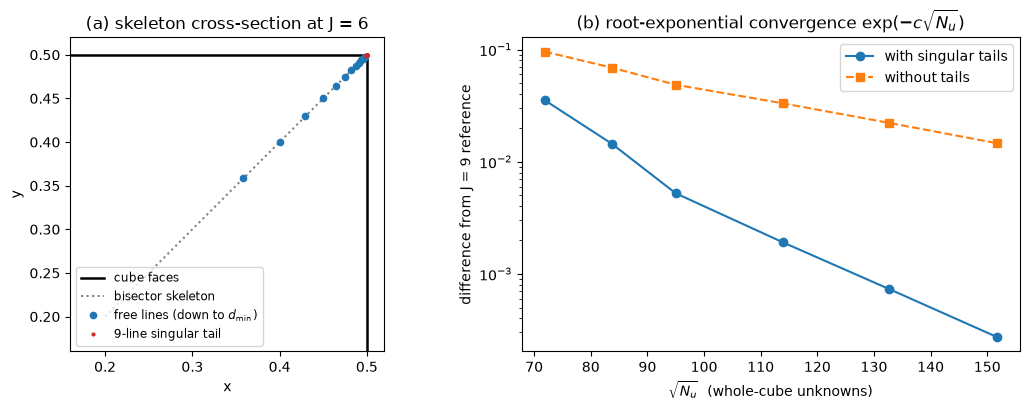

In [4]:
# Cross-section of one quadrant near the edge (x, y) = (1/2, 1/2) at level J = 6, and convergence with vs without tails
c6 = cube.Cube(6, classes=((1, -1, 1),))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot([0.15, 0.5, 0.5], [0.5, 0.5, 0.15], "k-", lw=1.8, label="cube faces")
ax1.plot([0.2, 0.5], [0.2, 0.5], ":", color="grey", label="bisector skeleton")
d_free = c6.depths / np.sqrt(2)
d_tail = c6.depths[-1] * 2.0 ** -np.arange(1, 10) / np.sqrt(2)
ax1.plot(0.5 - d_free, 0.5 - d_free, "o", color="tab:blue", ms=4.5, label=rf"free lines (down to $d_{{\min}}$)")
ax1.plot(0.5 - d_tail, 0.5 - d_tail, ".", color="tab:red", ms=4, label="9-line singular tail")
ax1.set(aspect="equal", xlim=(0.16, 0.52), ylim=(0.16, 0.52), xlabel="x", ylabel="y",
        title="(a) skeleton cross-section at J = 6")
ax1.legend(fontsize=8.5, loc="lower left")

rows = []
for J in range(2, 8):
    E, t, info = cube.solve(J, pts=pts)
    E0 = cube.solve(J, pts=pts, tails=False)[0]
    n_whole = 8 * info["unknowns"][0]          # 8 symmetry classes; standard wave solves 2 of them
    rows.append((n_whole, core.rel(E, ref), core.rel(E0, ref)))
    print(f"J = {J}: {n_whole:5d} whole-cube unknowns ({info['unknowns'][0]} per class), "
          f"error {rows[-1][1]:.1e} (no tail {rows[-1][2]:.1e}), {t:.1f} s")

rows = np.array(rows)
ax2.semilogy(np.sqrt(rows[:, 0]), rows[:, 1], "o-", label="with singular tails")
ax2.semilogy(np.sqrt(rows[:, 0]), rows[:, 2], "s--", label="without tails")
ax2.set(xlabel=r"$\sqrt{N_u}$  (whole-cube unknowns)", ylabel="difference from J = 9 reference",
        title=r"(b) root-exponential convergence $\exp(-c\sqrt{N_u})$")
ax2.legend()
fig.tight_layout()
plt.show()

## Effect of the singular tail right next to an edge
Evaluating the tangential boundary residual on the face $y = \tfrac12$ as a function of distance $\rho = \tfrac12 - x$ from the edge shows directly what the nine-line tail accomplishes (Figure 5 of the paper).

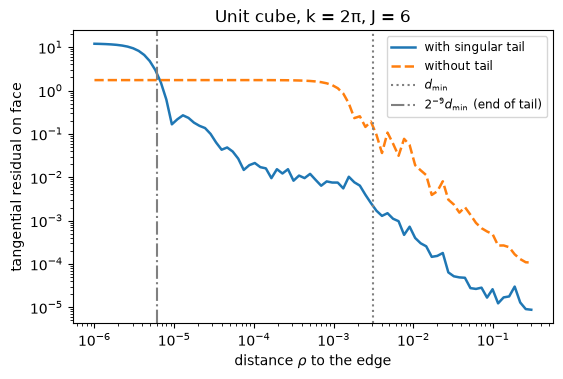

In [5]:
rho = np.logspace(-6, np.log10(0.3), 80)
x_edge = np.array([(0.5 - r, 0.5, z) for z in (0.05, 0.15, 0.25) for r in rho])
d0, p0 = core.wave()
inc_e = core.plane_wave(x_edge, 2 * np.pi, d0, p0)

fig, ax = plt.subplots(figsize=(6.2, 3.8))
for label, style, tails in (("with singular tail", "-", True), ("without tail", "--", False)):
    tot = cube.solve(6, d0, p0, pts=x_edge, tails=tails)[0] + inc_e
    rms = np.sqrt(np.mean(np.abs(tot[:, [0, 2]].reshape(3, len(rho), 2)) ** 2, axis=(0, 2)))
    ax.loglog(rho, rms, style, lw=1.8, label=label)
d_min = c6.depths[-1]
ax.axvline(d_min, ls=":", color="grey", label=r"$d_{\min}$")
ax.axvline(d_min * 2 ** -9, ls="-.", color="grey", label=r"$2^{-9}d_{\min}$ (end of tail)")
ax.set(xlabel=r"distance $\rho$ to the edge", ylabel="tangential residual on face", title="Unit cube, k = 2π, J = 6")
ax.legend(fontsize=8.5)
plt.show()

## Any incident wave
Mirror symmetry under $x \to -x$, $y \to -y$, $z \to -z$ splits any incident wave into eight octant parity classes, and $120^\circ$ rotation about a body diagonal relates four of those classes to two others, so at most four representative classes are needed (evaluated on 1/48 of the surface and split into $C_3$ and $y\leftrightarrow z$ blocks under $O_h$). Here is an oblique wave from polar angle $60^\circ$ and azimuth $25^\circ$, showing $|\mathbf{E}^{\mathrm{tot}}|$ in the plane $z = 0$.

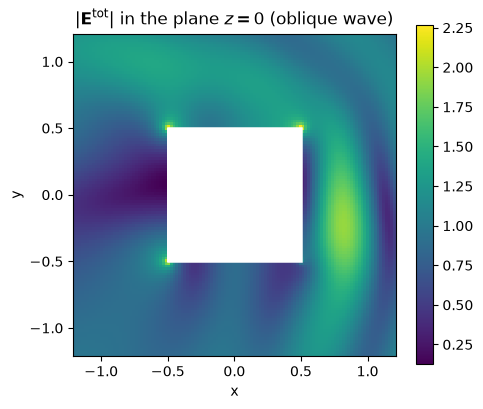

In [6]:
d, p = core.wave(60, 25, 35)
X, Y = np.meshgrid(np.linspace(-1.2, 1.2, 120), np.linspace(-1.2, 1.2, 120))
plane = np.column_stack((X.ravel(), Y.ravel(), 0 * X.ravel()))
outside = np.max(np.abs(plane), axis=1) > 0.5 + 1e-3
E = np.full((len(plane), 3), np.nan, complex)
E[outside] = cube.solve(6, d, p, pts=plane[outside])[0] + core.plane_wave(plane[outside], 2 * np.pi, d, p)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.pcolormesh(X, Y, np.linalg.norm(E, axis=1).reshape(X.shape), cmap="viridis", shading="auto")
ax.add_patch(plt.Rectangle((-0.5, -0.5), 1, 1, fill=False, edgecolor="white", lw=1.8))
ax.set(aspect="equal", xlabel="x", ylabel="y", title=r"$|\mathbf{E}^{\rm tot}|$ in the plane $z = 0$ (oblique wave)")
fig.colorbar(im, ax=ax)
plt.show()

## A second polyhedron: the regular tetrahedron
To verify that skeleton line sources and singular tails do not rely on orthogonal faces or rational wedge exponents, Section 5.6 of the paper (Figure 8) applies the same construction to the regular tetrahedron of unit edge length (interior dihedral angle $\arccos(1/3)\approx 70.53^\circ$, irrational wedge exponent $\gamma = \pi/\Phi \approx 0.621823$, and sharper corner exponent $\nu_1 = 0.32221$).

In [7]:
from mfs import tetrahedron

t_ref = tetrahedron.solve(8, pts=pts)[0]
for n_b in (4, 8):
    Et, _, _ = tetrahedron.solve(None, pts=pts, n_base=n_b)
    print(f"plain inner tetrahedron (n_base={n_b}): relative error {core.rel(Et, t_ref):.0%}")
for J in range(3, 8):
    Et, dt, info_t = tetrahedron.solve(J, pts=pts)
    print(f"skeleton + tails J = {J}: {sum(tetrahedron.Tetrahedron(J, classes=[]).unknowns.values()):5d} whole-body unknowns, "
          f"diff vs J=8 {core.rel(Et, t_ref):.1e}, optical {info_t['optical']:.1e}, {dt:.1f} s")

plain inner tetrahedron (n_base=4): relative error 63%
plain inner tetrahedron (n_base=8): relative error 53%


skeleton + tails J = 3:  4440 whole-body unknowns, diff vs J=8 2.2e-02, optical 8.1e-03, 2.3 s


skeleton + tails J = 4:  5484 whole-body unknowns, diff vs J=8 1.0e-02, optical 3.1e-03, 2.6 s


skeleton + tails J = 5:  7476 whole-body unknowns, diff vs J=8 4.5e-03, optical 1.3e-03, 5.1 s


skeleton + tails J = 6:  9888 whole-body unknowns, diff vs J=8 1.7e-03, optical 5.3e-04, 8.9 s


skeleton + tails J = 7: 12636 whole-body unknowns, diff vs J=8 5.3e-04, optical 2.3e-04, 13.7 s
